In [1]:
import numpy as np
import pandas as pd

raw_cols = ["Tot_Benes", "Tot_Srvcs", "Tot_Bene_Day_Srvcs",
            "Avg_Sbmtd_Chrg", "Avg_Mdcr_Alowd_Amt", "Avg_Mdcr_Pymt_Amt", "Avg_Mdcr_Stdzd_Amt"]
cols = ["Rndrng_NPI", "Rndrng_Prvdr_Type", "HCPCS_Cd", "Place_Of_Srvc", "Rndrng_Prvdr_Cntry"] + raw_cols
df = pd.read_parquet("medicare_2024.parquet", columns=cols)

# same cleaning as common_setup.ipynb
keep = ((df["Rndrng_Prvdr_Cntry"] == "US")
        & (df["Tot_Srvcs"] >= df["Tot_Benes"])
        & (df["Tot_Bene_Day_Srvcs"] <= df["Tot_Srvcs"])
        & (df["Avg_Mdcr_Alowd_Amt"] > 0))
df = df[keep].reset_index(drop=True)
df["row_id"] = np.arange(len(df))

# peer levels from the common setup (min group size 100)
peers = pd.read_parquet("data/processed/peers_100.parquet")
df = df.merge(peers[["row_id", "peer_level"]], on="row_id", how="left")
len(df)

9781161

## Features and feature sets

In [2]:
# log of every raw column
for c in raw_cols:
    df["log_" + c] = np.log(df[c].clip(lower=1e-6))

# our engineered features
df["srvcs_per_bene"] = np.log(df["Tot_Srvcs"] / df["Tot_Benes"])  # intensity
df["markup"] = np.log(df["Avg_Sbmtd_Chrg"].clip(lower=1e-6) / df["Avg_Mdcr_Alowd_Amt"])  # charge vs allowed

sets = {
    "A: all 7 raw": ["log_" + c for c in raw_cols],
    "B: 4 raw": ["log_Tot_Benes", "log_Tot_Srvcs", "log_Avg_Sbmtd_Chrg", "log_Avg_Mdcr_Stdzd_Amt"],
    "C: ours (2 raw + 2 FE)": ["log_Avg_Mdcr_Stdzd_Amt", "log_Tot_Benes", "srvcs_per_bene", "markup"],
}
# columns that measure the same thing (volume or price)
blocks = {
    "A: all 7 raw": [["log_Tot_Benes", "log_Tot_Srvcs", "log_Tot_Bene_Day_Srvcs"],
                     ["log_Avg_Sbmtd_Chrg", "log_Avg_Mdcr_Alowd_Amt", "log_Avg_Mdcr_Pymt_Amt", "log_Avg_Mdcr_Stdzd_Amt"]],
    "B: 4 raw": [["log_Tot_Benes", "log_Tot_Srvcs"],
                 ["log_Avg_Sbmtd_Chrg", "log_Avg_Mdcr_Stdzd_Amt"]],
    "C: ours (2 raw + 2 FE)": [[c] for c in sets["C: ours (2 raw + 2 FE)"]],  # each feature is its own block
}

## Robust z for each set

In [3]:
levels = {1: ["Rndrng_Prvdr_Type", "HCPCS_Cd", "Place_Of_Srvc"],
          2: ["HCPCS_Cd", "Place_Of_Srvc"],
          3: ["HCPCS_Cd"]}
gids = {lvl: df.groupby(keys, observed=True).ngroup() for lvl, keys in levels.items()}  # group id on each level

def robust_z(cols):
    out = pd.DataFrame(np.nan, index=df.index, columns=cols, dtype="float32")
    for c in cols:  # one column at a time to save memory
        for lvl in [1, 2, 3]:
            g = gids[lvl]
            med = df[c].groupby(g).transform("median")
            dev = (df[c] - med).abs()
            mad = dev.groupby(g).transform("median")
            mean_dev = dev.groupby(g).transform("mean")
            scale = (1.4826 * mad).where(mad > 0, 1.2533 * mean_dev)  # if MAD = 0, use mean abs deviation
            z = (df[c] - med) / scale.where(scale > 0)
            rows = df["peer_level"] == lvl  # only rows that use this level
            out.loc[rows, c] = z[rows].astype("float32")
    return out

rz = {name: robust_z(cols) for name, cols in sets.items()}

## 1. Within-group correlation

In [4]:
scored = df["peer_level"] > 0
sample = scored[scored].sample(500_000, random_state=0).index if scored.sum() > 500_000 else scored[scored].index

for name in sets:
    corr = rz[name].loc[sample].corr()  # z-scores are already relative to the group
    print(name)
    display(corr.round(2))

A: all 7 raw


,log_Tot_Benes,log_Tot_Srvcs,log_Tot_Bene_Day_Srvcs,log_Avg_Sbmtd_Chrg,log_Avg_Mdcr_Alowd_Amt,log_Avg_Mdcr_Pymt_Amt,log_Avg_Mdcr_Stdzd_Amt
log_Tot_Benes,1.00,0.95,0.96,-0.00,0.00,0.00,0.00
log_Tot_Srvcs,0.95,1.00,0.99,-0.01,0.00,0.00,0.00
log_Tot_Bene_Day_Srvcs,0.96,0.99,1.00,-0.00,0.00,0.00,0.00
log_Avg_Sbmtd_Chrg,-0.00,-0.01,-0.00,1.00,0.01,0.00,0.00
log_Avg_Mdcr_Alowd_Amt,0.00,0.00,0.00,0.01,1.00,0.99,0.02
log_Avg_Mdcr_Pymt_Amt,0.00,0.00,0.00,0.00,0.99,1.00,0.02
log_Avg_Mdcr_Stdzd_Amt,0.00,0.00,0.00,0.00,0.02,0.02,1.00


B: 4 raw


,log_Tot_Benes,log_Tot_Srvcs,log_Avg_Sbmtd_Chrg,log_Avg_Mdcr_Stdzd_Amt
log_Tot_Benes,1.00,0.95,-0.00,0.0
log_Tot_Srvcs,0.95,1.00,-0.01,0.0
log_Avg_Sbmtd_Chrg,-0.00,-0.01,1.00,0.0
log_Avg_Mdcr_Stdzd_Amt,0.00,0.00,0.00,1.0


C: ours (2 raw + 2 FE)


,log_Avg_Mdcr_Stdzd_Amt,log_Tot_Benes,srvcs_per_bene,markup
log_Avg_Mdcr_Stdzd_Amt,1.0,0.00,-0.00,-0.0
log_Tot_Benes,0.0,1.00,0.06,-0.0
srvcs_per_bene,-0.0,0.06,1.00,-0.0
markup,-0.0,-0.00,-0.00,1.0


## 2. Baseline flags and double counting

In [5]:
def baseline(z):
    high = z.clip(lower=0).fillna(0)  # only above peers
    z_sorted = np.sort(high.to_numpy(), axis=1)  # each row sorted ascending
    top1 = z_sorted[:, -1]  # largest z
    top2 = z_sorted[:, -2]  # 2nd largest z
    flag = (top1 > 10) | (top2 > 3.5)  # 1 feature > 10 or 2+ features > 3.5
    score = np.maximum(top2, top1 * 3.5 / 10)  # one number per row for ranking (> 3.5 = flagged)
    return pd.Series(score, index=z.index).where(scored), pd.Series(flag, index=z.index) & scored

scores, flags = {}, {}
for name in sets:
    scores[name], flags[name] = baseline(rz[name])

In [6]:
def double_counted(z, flag, set_blocks):
    over = z > 3.5
    n_high = sum(over[b].any(axis=1) for b in set_blocks)  # how many different things are high
    no_extreme = z.max(axis=1) <= 10  # not flagged by the "1 feature > 10" part
    return flag & no_extreme & (n_high == 1)  # flagged only because one thing was counted twice

rows = []
for name in sets:
    dbl = double_counted(rz[name], flags[name], blocks[name])
    rows.append({"feature set": name,
                 "n features": len(sets[name]),
                 "flag %": flags[name].mean() * 100,
                 "double-counted % of flags": dbl.sum() / flags[name].sum() * 100})

results = pd.DataFrame(rows).set_index("feature set").round(2)
results

,n features,flag %,double-counted % of flags
feature set,,,
A: all 7 raw,7,0.99,70.75
B: 4 raw,4,0.60,53.89
C: ours (2 raw + 2 FE),4,1.24,0.00


## 3. Overlap of the top 1%

In [7]:
def top_overlap(a, b, q=0.01):
    ta = a >= a.quantile(1 - q)
    tb = b >= b.quantile(1 - q)
    return (ta & tb).sum() / ta.sum() * 100

names = list(sets)
overlap = pd.DataFrame({a: {b: top_overlap(scores[a], scores[b]) for b in names} for a in names}).round(1)
overlap  # % of top 1% shared between feature sets

,A: all 7 raw,B: 4 raw,C: ours (2 raw + 2 FE)
A: all 7 raw,100.0,66.8,28.1
B: 4 raw,66.8,100.0,28.0
C: ours (2 raw + 2 FE),28.1,28.0,100.0


In [8]:
# example: flagged in A only because one thing is counted in several columns
A = "A: all 7 raw"
C = "C: ours (2 raw + 2 FE)"

dbl_A = double_counted(rz[A], flags[A], blocks[A])  # double-counted flags in A
example = dbl_A & ~flags[C]  # and not flagged with our features

ex = rz[A][example].round(1).head(5)
ex

,log_Tot_Benes,log_Tot_Srvcs,log_Tot_Bene_Day_Srvcs,log_Avg_Sbmtd_Chrg,log_Avg_Mdcr_Alowd_Amt,log_Avg_Mdcr_Pymt_Amt,log_Avg_Mdcr_Stdzd_Amt
1163,3.6,2.8,3.6,-0.0,0.5,0.5,-0.1
1251,6.3,4.7,4.7,-0.3,-0.2,-0.6,-3.8
1263,4.3,4.3,4.3,-0.1,0.3,0.7,0.7
1298,3.2,3.8,3.8,-0.1,0.5,0.5,-0.0
1573,0.6,0.1,0.1,-1.5,9.7,5.0,0.6


## 4. Checking payment_to_allowed as a 5th feature

Add payment / allowed to our 4 features and look at the new flags it creates.

In [9]:
# add payment_to_allowed to our 4 features
df["payment_to_allowed"] = np.log(df["Avg_Mdcr_Pymt_Amt"].clip(lower=1e-6) / df["Avg_Mdcr_Alowd_Amt"])
C = "C: ours (2 raw + 2 FE)"
z_pta = robust_z(["payment_to_allowed"])["payment_to_allowed"]
_, flag_D = baseline(rz[C].assign(payment_to_allowed=z_pta))

new = flag_D & ~flags[C]  # flags that appear only because we added it
ratio = df["Avg_Mdcr_Pymt_Amt"] / df["Avg_Mdcr_Alowd_Amt"] * 100  # % of allowed that Medicare pays
peer_med = ratio.groupby(gids[1]).transform("median")  # level 1 peer median

print(f"flag rate: 4 features {flags[C].mean() * 100:.2f}%, with payment_to_allowed {flag_D.mean() * 100:.2f}%")
print(f"new flags: {new.sum():,} ({new.sum() / flag_D.sum() * 100:.1f}% of all flags)")
print(f"new flags driven by this feature alone (z > 10): {(z_pta[new] > 10).mean() * 100:.1f}%")
print(f"median gap from peer median: {(ratio - peer_med)[new].abs().median():.1f} percentage points")

flag rate: 4 features 1.24%, with payment_to_allowed 1.76%
new flags: 51,306 (29.7% of all flags)
new flags driven by this feature alone (z > 10): 86.4%
median gap from peer median: 0.8 percentage points


### Values across all rows and spread inside peer groups

In [ ]:
display(ratio[scored].quantile([0.05, 0.25, 0.5, 0.75, 0.95]).round(1).rename("payment / allowed (%)"))

g = ratio.groupby(gids[1])
iqr = g.quantile(0.75) - g.quantile(0.25)  # spread inside each level 1 peer group
print(f"median IQR inside peer groups: {iqr.median():.2f} pp, groups with IQR = 0: {(iqr == 0).mean() * 100:.0f}%")

0.05     62.7
0.25     72.9
0.50     78.0
0.75     79.7
0.95    100.0
Name: payment / allowed (%), dtype: float64

median IQR inside peer groups: 0.08 pp, groups with IQR = 0: 44%


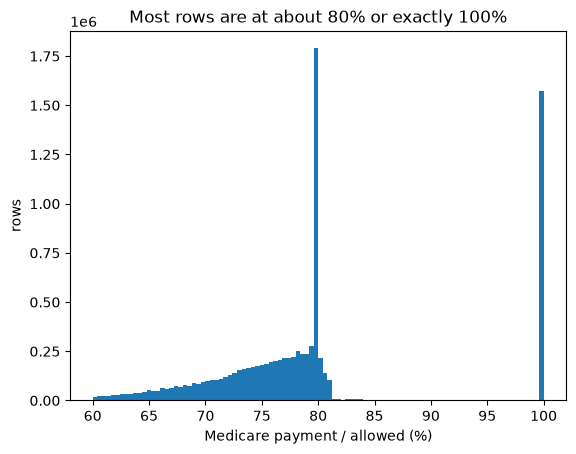

In [11]:
import matplotlib.pyplot as plt

plt.hist(ratio[scored], bins=100, range=(60, 100))
plt.xlabel("Medicare payment / allowed (%)")
plt.ylabel("rows")
plt.title("Most rows are at about 80% or exactly 100%")
plt.show()

### Rows at 100% (no patient coinsurance)

In [12]:
full = ratio >= 99.9
print(f"rows at 100%: {full[scored].mean() * 100:.1f}%")
df.loc[full, "HCPCS_Cd"].value_counts().head(5)  # vaccines, wellness visit, lab tests

rows at 100%: 16.2%


HCPCS_Cd
G0008    112086
G0439    110720
36415     86022
90662     70756
90480     54809
Name: count, dtype: int64